# hklforge quickstart

hklforge computes diffractometer angles for **any geometry you declare**, and
returns **every** solution of a mode in closed form - no numerical search,
so no missed branches. This notebook goes through the basics on the psic
six-circle (You 1999, as in diffcalc) and compares with diffcalc on the way.

Further notebooks: [02 virtual angles](02_virtual_angles.ipynb),
[03 diffcalc comparison](03_diffcalc_comparison.ipynb),
[04 double diffraction](04_double_diffraction.ipynb),
[05 custom geometries](05_custom_geometries.ipynb). Definitions are in
[docs/virtual_angles.md](../docs/virtual_angles.md), modes in
[docs/modes.md](../docs/modes.md).

In [1]:
import sys, os, logging, warnings
sys.path.insert(0, os.path.abspath("../src"))      # hklforge from this repository
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hklforge import Diffractometer, Geometry, ModeError, Degenerate
from hklforge.lattice import b_matrix
from hklforge.draw import draw, draw_circles
logging.getLogger("diffcalc").setLevel(logging.ERROR)
pd.set_option("display.precision", 3)
%matplotlib inline

## A geometry

Two stacks of circles, outermost first, each a right-handed rotation about a
fixed lab axis (given at all angles zero). psic: lab x vertical, y along the
beam, z transverse.

Geometry('psic': sample [mu(x+), eta(z-), chi(y+), phi(z-)] | detector [nu(x+), delta(z-)] | beam (y+))


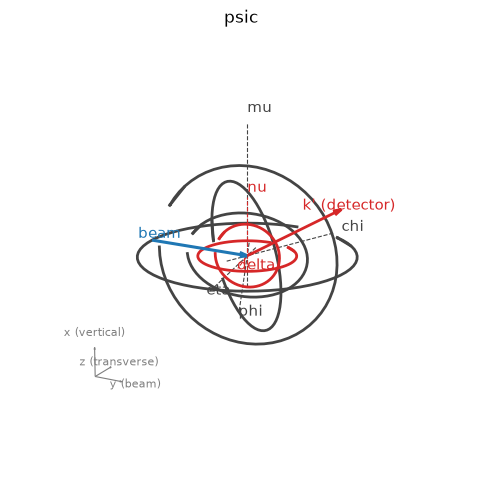

In [2]:
psic = Geometry.builtin("psic")
print(psic)
draw_circles(psic, {"mu": 10, "eta": 20, "chi": 30, "phi": 0, "nu": 15, "delta": 30});

## A crystal

UB is in the phi frame with q = UB h, |q| = 2π/d (the convention of diffcalc and libhkl).
Here: silicon, U = identity, 9 keV, surface normal along (0 0 1).

In [3]:
si = (5.431, 5.431, 5.431, 90, 90, 90)
ub = np.eye(3) @ b_matrix(*si)
d = Diffractometer(psic, ub, energy=9000, surface_hkl=(0, 0, 1), reference_hkl=(0, 0, 1))
print(f"wavelength {d.wavelength:.4f} A, |k| = {d.k:.4f} 1/A")

wavelength 1.3776 A, |k| = 4.5610 1/A


## Solving: a mode is what you hold

As in diffcalc, a dict of circle values and virtual-angle constraints. The
Bernina default - eta, chi, phi held - leaves mu and the two detector circles:

In [4]:
mode = {"eta": 0, "chi": 0, "phi": 0}
sols = d.solve((1, 1, 1), mode)
pd.DataFrame(sols)

,mu,eta,chi,phi,nu,delta
0,60.607,0.0,0.0,0.0,-159.073,165.306
1,60.607,0.0,0.0,0.0,20.927,14.694
2,-150.607,0.0,0.0,0.0,159.073,165.306
3,-150.607,0.0,0.0,0.0,-20.927,14.694


Every solution, re-checked through the forward model. The plan says how it was found:

In [5]:
print(d.plan(mode).describe())

psic: eta=0.0, chi=0.0, phi=0.0, detector on h1  [beam]
  1. Bragg b.R q = -|q|^2/2k: one projection equation in mu (<= 2)
  2. k' = b + R q / k; detector (nu, delta): sp2 (<= 2)


The virtual angles of each solution ([definitions](../docs/virtual_angles.md)):

In [6]:
pd.DataFrame([d.pseudo(s) for s in sols])

,theta,ttheta,qaz,betain,betaout,alpha,beta,naz,tau,psi,omega
0,12.69,25.38,36.285,60.607,-38.143,60.607,-38.143,-7.148e-15,54.736,159.162,42.364
1,12.69,25.38,36.285,60.607,-38.143,60.607,-38.143,-7.148e-15,54.736,159.162,42.364
2,12.69,25.38,143.715,-29.393,48.112,-29.393,48.112,-1.800e+02,54.736,-39.162,142.889
3,12.69,25.38,143.715,-29.393,48.112,-29.393,48.112,-1.800e+02,54.736,-39.162,142.889


## More modes

Fixed incidence, psi, a scattering-plane azimuth, bisecting, a second reflection:

In [7]:
modes = [
    {"eta": 0, "chi": 0, "phi": 0},
    {"chi": 10, "phi": 20, "betain": 2},
    {"mu": 0, "nu": 0, "betain": 2},
    {"mu": 0, "nu": 0, "psi": 30},
    {"qaz": 90, "mu": 0, "phi": 0},
    {"naz": 30, "alpha": 5, "phi": 0},
    {"nu": 0, "bisect": True, "omega": 0},
    {"delta": 40, "mu": 0, "bisect": True},
    {"mu": 0, "nu": 0, "h2": (2, 2, 0)},
]
rows = []
for m in modes:
    p = d.plan(m)
    rows.append({"mode": m, "case": p.case, "solutions": len(d.solve((1, 1, 3), m))})
pd.DataFrame(rows)

,mode,case,solutions
0,"{'eta': 0, 'chi': 0, 'phi': 0}",beam,4
1,"{'chi': 10, 'phi': 20, 'betain': 2}",beam_x,8
2,"{'mu': 0, 'nu': 0, 'betain': 2}",q_x,8
3,"{'mu': 0, 'nu': 0, 'psi': 30}",q_x,4
4,"{'qaz': 90, 'mu': 0, 'phi': 0}",q,4
5,"{'naz': 30, 'alpha': 5, 'phi': 0}",beam_x_naz,8
6,"{'nu': 0, 'bisect': True, 'omega': 0}",axis,8
7,"{'delta': 40, 'mu': 0, 'bisect': True}",axis,8
8,"{'mu': 0, 'nu': 0, 'h2': (2, 2, 0)}",q_x,8


## A drawing of one solution

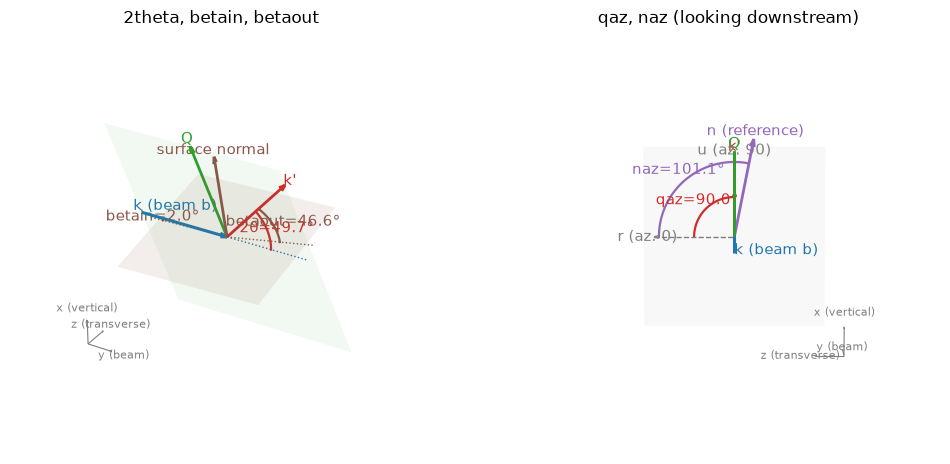

In [8]:
s = d.solve((1, 1, 3), {"mu": 0, "nu": 0, "betain": 2})[0]
fig = plt.figure(figsize=(12, 5.5))
draw(d, s, show=("ttheta", "betain", "betaout"), ax=fig.add_subplot(1, 2, 1, projection="3d"),
     title="2theta, betain, betaout")
draw(d, s, show=("qaz", "naz"), view="beam", ax=fig.add_subplot(1, 2, 2, projection="3d"),
     title="qaz, naz (looking downstream)");

## Side by side with diffcalc

Same lattice, same U, same normals. diffcalc returns angles beyond ±180, so
the sets are compared with wrapping.

In [9]:
from diffcalc.ub.calc import UBCalculation
from diffcalc.hkl.calc import HklCalculation
from diffcalc.hkl.constraints import Constraints
from diffcalc.hkl.geometry import Position
from diffcalc.util import DiffcalcException

import contextlib, io

def diffcalc_ubcalc(lattice, U=np.eye(3), surface=None, reference=None):
    ubc = UBCalculation("example")
    ubc.set_lattice("x", *lattice)
    with contextlib.redirect_stdout(io.StringIO()):     # diffcalc prints "Calculating UB matrix."
        ubc.set_u(U)
    if surface is not None:
        ubc.surf_nphi = tuple(np.asarray(surface) / np.linalg.norm(surface))
    if reference is not None:
        ubc.n_phi = tuple(np.asarray(reference) / np.linalg.norm(reference))
    return ubc

def diffcalc_solve(ubc, hkl, mode, wavelength):
    """diffcalc's positions as dicts, [] if it finds none, or the error text."""
    try:
        return [p.asdict for p, _ in HklCalculation(ubc, Constraints(mode)).get_position(*hkl, wavelength)]
    except DiffcalcException as e:
        msg = " ".join(str(e).replace("*", " ").split())
        if "No solutions" in msg or "prohibits a solution" in msg:
            return []
        return msg
    except (AssertionError, ValueError) as e:
        return f"{type(e).__name__}: {e}"

def same(a, b, tol=1e-5):
    return all(abs((a[n] - b[n] + 180) % 360 - 180) < tol for n in a)

def same_set(xs, ys):
    return all(any(same(x, y) for y in ys) for x in xs) and all(any(same(y, x) for x in xs) for y in ys)

In [10]:
ubc = diffcalc_ubcalc(si, surface=(0, 0, 1), reference=(0, 0, 1))
print("same UB as diffcalc:", np.allclose(ubc.UB, ub))
rows = []
for m in modes[:-1]:                                    # diffcalc has no second reflection
    mine = d.solve((1, 1, 3), m)
    theirs = diffcalc_solve(ubc, (1, 1, 3), m, d.wavelength)
    rows.append({"mode": m, "hklforge": len(mine),
                 "diffcalc": theirs if isinstance(theirs, str) else len(theirs),
                 "identical sets": None if isinstance(theirs, str) else same_set(mine, theirs)})
pd.DataFrame(rows)

same UB as diffcalc: True


,mode,hklforge,diffcalc,identical sets
0,"{'eta': 0, 'chi': 0, 'phi': 0}",4,4,True
1,"{'chi': 10, 'phi': 20, 'betain': 2}",8,8,True
2,"{'mu': 0, 'nu': 0, 'betain': 2}",8,8,True
3,"{'mu': 0, 'nu': 0, 'psi': 30}",4,4,True
4,"{'qaz': 90, 'mu': 0, 'phi': 0}",4,4,True
5,"{'naz': 30, 'alpha': 5, 'phi': 0}",8,8,True
6,"{'nu': 0, 'bisect': True, 'omega': 0}",8,8,True
7,"{'delta': 40, 'mu': 0, 'bisect': True}",8,16,True


In the last row diffcalc lists each of its 8 positions twice (the sets are equal). In other
bisect modes it also returns positions that violate the mode (see
[03 diffcalc comparison](03_diffcalc_comparison.ipynb)) - e.g. delta held, omega = 25:

In [11]:
from hklforge.virtual import bisect_axis
m = {"delta": 30, "bisect": True, "omega": 25}
theirs = diffcalc_solve(ubc, (1, 1, 3), m, d.wavelength)
mine = d.solve((1, 1, 3), m)
rows = []
for a in theirs:
    e, Q = bisect_axis(psic, a), psic.q_lab(a, 1.0)
    rows.append({"chi axis out of scattering plane": e @ np.cross(psic.beam, Q / np.linalg.norm(Q)),
                 "omega": d.pseudo(a)["omega"], "also found by hklforge": any(same(a, b) for b in mine)})
pd.DataFrame(rows)

,chi axis out of scattering plane,omega,also found by hklforge
0,9.439e-18,25.000,True
1,9.439e-18,25.000,True
2,6.867e-01,164.666,False
3,6.867e-01,164.666,False
4,6.867e-01,164.666,False
5,6.867e-01,164.666,False
6,-2.126e-16,25.000,True
7,-2.126e-16,25.000,True
8,-9.439e-18,25.000,True
9,-9.439e-18,25.000,True


## Modes that do not work are explained

In [12]:
for m in [{"eta": 0, "chi": 0}, {"eta": 0, "betain": 1, "betaout": 2}, {"nu": 0, "delta": 0, "eta": 0},
          {"eta": 0, "chi": 0, "omega": 0}]:
    try:
        d.plan(m)
    except ModeError as e:
        print(m, "->", e, "\n")
try:
    d.solve((1, 1, 1), {"mu": 0, "chi": 0, "qaz": 90})
except Degenerate as e:
    print("Degenerate:", e)

{'eta': 0, 'chi': 0} -> 2 free sample circles ['mu', 'phi'] with 2 free detector circles and 0 constraint(s) on the sample is underdetermined (a continuum of positions); need 1 

{'eta': 0, 'betain': 1, 'betaout': 2} -> ['betain', 'betaout']: each of these fixes the beam direction seen from the sample, which Bragg already constrains; at most one can be used 

{'nu': 0, 'delta': 0, 'eta': 0} -> all detector circles held: that fixes |Q|, so a general hkl is unreachable 

{'eta': 0, 'chi': 0, 'omega': 0} -> ['omega'] need the scattering plane first: hold one detector circle or give qaz 

Degenerate: the two directions are parallel (free: eta, phi, nu, delta; held: mu=0, chi=0)
